# Price XGBoost + Extra Trees stacking experiment

Run this standalone Colab notebook after both price base-model notebooks. It reads their saved validation and test predictions, fits a Ridge meta-model on validation predictions, and compares XGBoost, Extra Trees, and stacking on the untouched test predictions.

**Important:** this is an exploratory comparison. Validation base predictions came from train-only models, while test base predictions came from models refitted on train plus validation. The Ridge file alone is not a deployable price pipeline. A production stack requires time-ordered out-of-fold base predictions and access to both fitted base models during future prediction.

In [1]:
%pip install -q pandas scikit-learn==1.6.1 joblib==1.6.0 matplotlib seaborn

## Mount Drive and locate base-model predictions

No price training or future-feature CSV is needed. The XGBoost and Extra Trees notebooks must already have saved their four prediction files under `MyDrive/demand-forecasting/artifacts/price/predictions`.

In [2]:
import json
import platform
import shutil
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from google.colab import drive
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

drive.mount("/content/drive")
DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/demand-forecasting")
DRIVE_ARTIFACT_DIR = DRIVE_PROJECT_DIR / "artifacts" / "price"
PREDICTION_DIR = DRIVE_ARTIFACT_DIR / "predictions"
LOCAL_ARTIFACT_DIR = Path("/content/price_stacking_artifacts")
INPUT_FILES = {
    ("xgboost", "validation"): PREDICTION_DIR / "xgboost_validation_predictions.csv",
    ("etr", "validation"): PREDICTION_DIR / "etr_validation_predictions.csv",
    ("xgboost", "test"): PREDICTION_DIR / "xgboost_test_predictions.csv",
    ("etr", "test"): PREDICTION_DIR / "etr_test_predictions.csv",
}

missing_files = [str(path) for path in INPUT_FILES.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError("Run both price base-model notebooks first. Missing:\n" + "\n".join(missing_files))

print("All four prediction files found:")
for path in INPUT_FILES.values():
    print(path)

Mounted at /content/drive
All four prediction files found:
/content/drive/MyDrive/demand-forecasting/artifacts/price/predictions/xgboost_validation_predictions.csv
/content/drive/MyDrive/demand-forecasting/artifacts/price/predictions/etr_validation_predictions.csv
/content/drive/MyDrive/demand-forecasting/artifacts/price/predictions/xgboost_test_predictions.csv
/content/drive/MyDrive/demand-forecasting/artifacts/price/predictions/etr_test_predictions.csv


## Align and validate identical forecast rows

Rows are matched by forecast origin, target month, crop, location, and horizon. The notebook stops if it finds duplicate keys, missing rows, different actual prices, non-finite values, or overlapping validation and test months.

In [3]:
KEY_COLUMNS = ["forecast_origin_month", "target_month", "crop", "location", "forecast_horizon"]
TARGET_COLUMN = "future_weighted_avg_procurement_price_rm_per_kg"
META_FEATURES = ["xgboost_prediction", "etr_prediction"]

def load_prediction(model_name, split_name):
    frame = pd.read_csv(
        INPUT_FILES[(model_name, split_name)],
        parse_dates=["forecast_origin_month", "target_month"],
    )
    prediction_column = "xgboost_prediction" if model_name == "xgboost" else "etr_prediction"
    required = KEY_COLUMNS + [TARGET_COLUMN, prediction_column, "split"]
    missing = [column for column in required if column not in frame.columns]
    if missing:
        raise ValueError(f"{model_name} {split_name} is missing columns: {missing}")
    if frame.empty or frame[required].isna().any().any():
        raise ValueError(f"{model_name} {split_name} contains no rows or missing required values.")
    if frame.duplicated(KEY_COLUMNS).any():
        raise ValueError(f"{model_name} {split_name} contains duplicate forecast keys.")
    if not frame["split"].eq(split_name).all():
        raise ValueError(f"{model_name} {split_name} contains incorrect split labels.")
    if not np.isfinite(frame[[TARGET_COLUMN, prediction_column]].to_numpy(dtype=float)).all():
        raise ValueError(f"{model_name} {split_name} contains non-finite prices or predictions.")
    return frame[KEY_COLUMNS + [TARGET_COLUMN, prediction_column]].copy()

def align_split(split_name):
    xgboost_frame = load_prediction("xgboost", split_name)
    etr_frame = load_prediction("etr", split_name).rename(columns={TARGET_COLUMN: "etr_actual"})
    joined = xgboost_frame.merge(etr_frame, on=KEY_COLUMNS, how="outer", validate="one_to_one", indicator=True)
    if len(joined) != len(xgboost_frame) or len(joined) != len(etr_frame) or not joined["_merge"].eq("both").all():
        raise ValueError(f"{split_name} XGBoost and Extra Trees prediction keys do not match exactly.")
    if not np.allclose(joined[TARGET_COLUMN], joined["etr_actual"], rtol=0, atol=1e-8):
        raise ValueError(f"{split_name} actual prices differ between model files.")
    return joined.drop(columns=["etr_actual", "_merge"]).sort_values(KEY_COLUMNS).reset_index(drop=True)

validation = align_split("validation")
test = align_split("test")
if validation["target_month"].max() >= test["target_month"].min():
    raise ValueError("Validation and test target months overlap or are out of order.")
if set(validation["forecast_horizon"]) != set(range(1, 13)) or set(test["forecast_horizon"]) != set(range(1, 13)):
    raise ValueError("Both splits must contain every H1–H12 horizon.")

print(f"Validation: {len(validation):,} rows, {validation.target_month.min().date()} to {validation.target_month.max().date()}")
print(f"Test: {len(test):,} rows, {test.target_month.min().date()} to {test.target_month.max().date()}")

Validation: 1,620 rows, 2025-07-01 to 2025-09-01
Test: 1,620 rows, 2025-10-01 to 2025-12-01


## Fit the Ridge meta-model

Ridge receives only two inputs: the XGBoost and Extra Trees validation predictions. `alpha=1.0` is fixed before looking at test results. The stacking validation metrics are in-sample diagnostics and must not be interpreted as an unbiased validation score.

In [4]:
RIDGE_ALPHA = 1.0
stacker = Ridge(alpha=RIDGE_ALPHA)
stacker.fit(validation[META_FEATURES], validation[TARGET_COLUMN])
validation["stacking_prediction"] = np.maximum(stacker.predict(validation[META_FEATURES]), 0)
test["stacking_prediction"] = np.maximum(stacker.predict(test[META_FEATURES]), 0)

print(f"Intercept: {stacker.intercept_:.6f}")
print("Coefficients:", dict(zip(META_FEATURES, stacker.coef_)))
print("Ridge coefficients are not automatically percentage weights; they may be negative or sum to more than one.")

Intercept: 0.091514
Coefficients: {'xgboost_prediction': np.float64(0.5844476589365378), 'etr_prediction': np.float64(0.39395974938823)}
Ridge coefficients are not automatically percentage weights; they may be negative or sum to more than one.


## Compare all three models

Lower MAE, RMSE, and WAPE are better. Higher R² is better. Use the untouched test comparison for the final experiment result, but do not repeatedly tune the stack against this same test period.

In [5]:
from IPython.display import display

MODEL_COLUMNS = {
    "xgboost": "xgboost_prediction",
    "extra_trees": "etr_prediction",
    "stacking": "stacking_prediction",
}

def score(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    denominator = np.abs(actual).sum()
    return {
        "mae": float(mean_absolute_error(actual, predicted)),
        "rmse": float(np.sqrt(mean_squared_error(actual, predicted))),
        "wape": float(np.abs(actual - predicted).sum() / denominator) if denominator > 0 else np.nan,
        "r2": float(r2_score(actual, predicted)),
    }

records = []
for split_name, frame in [("validation", validation), ("test", test)]:
    for model_name, prediction_column in MODEL_COLUMNS.items():
        records.append({"model": model_name, "split": split_name, "forecast_horizon": "overall", "rows": len(frame), **score(frame[TARGET_COLUMN], frame[prediction_column])})
        for horizon, group in frame.groupby("forecast_horizon"):
            records.append({"model": model_name, "split": split_name, "forecast_horizon": int(horizon), "rows": len(group), **score(group[TARGET_COLUMN], group[prediction_column])})

metrics = pd.DataFrame(records)
print("Overall metrics (stacking validation result is in-sample):")
display(metrics[metrics["forecast_horizon"].eq("overall")].sort_values(["split", "mae"]))
print("Test metrics by horizon:")
display(metrics[(metrics["split"].eq("test")) & (metrics["forecast_horizon"].ne("overall"))])

Overall metrics (stacking validation result is in-sample):


,model,split,forecast_horizon,rows,mae,rmse,wape,r2
39,xgboost,test,overall,1620,0.150842,0.197670,0.033042,0.988239
65,stacking,test,overall,1620,0.152447,0.204395,0.033394,0.987425
52,extra_trees,test,overall,1620,0.168337,0.211286,0.036875,0.986563
26,stacking,validation,overall,1620,0.118056,0.154175,0.027669,0.991697
0,xgboost,validation,overall,1620,0.123853,0.161309,0.029028,0.990911
13,extra_trees,validation,overall,1620,0.139359,0.178828,0.032662,0.988829


Test metrics by horizon:


,model,split,forecast_horizon,rows,mae,rmse,wape,r2
40,xgboost,test,1,135,0.154158,0.201345,0.033769,0.987797
41,xgboost,test,2,135,0.153879,0.199631,0.033708,0.988004
42,xgboost,test,3,135,0.154052,0.200926,0.033745,0.987848
43,xgboost,test,4,135,0.150187,0.198449,0.032899,0.988146
44,xgboost,test,5,135,0.158518,0.204801,0.034724,0.987375
45,xgboost,test,6,135,0.152753,0.200274,0.033461,0.987927
46,xgboost,test,7,135,0.147792,0.197054,0.032374,0.988312
47,xgboost,test,8,135,0.154646,0.202527,0.033876,0.987654
48,xgboost,test,9,135,0.149980,0.198454,0.032854,0.988145
49,xgboost,test,10,135,0.146083,0.191086,0.032000,0.989009


## Visualize the test comparison

The same three graph types used by the base-model notebooks now compare all three methods.

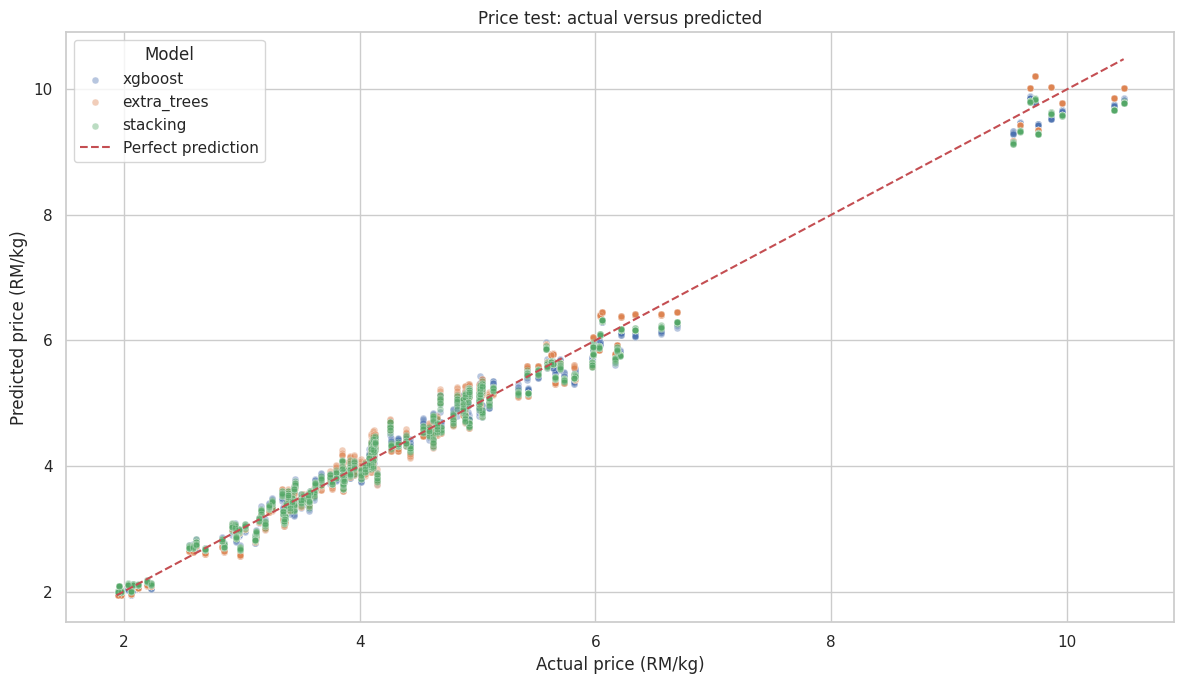

In [6]:
sns.set_theme(style="whitegrid")
actual = test[TARGET_COLUMN]
lower = min(actual.min(), *(test[column].min() for column in MODEL_COLUMNS.values()))
upper = max(actual.max(), *(test[column].max() for column in MODEL_COLUMNS.values()))
plt.figure(figsize=(12, 7))
for model_name, prediction_column in MODEL_COLUMNS.items():
    sns.scatterplot(x=actual, y=test[prediction_column], alpha=0.4, s=24, label=model_name)
plt.plot([lower, upper], [lower, upper], "r--", label="Perfect prediction")
plt.title("Price test: actual versus predicted")
plt.xlabel("Actual price (RM/kg)")
plt.ylabel("Predicted price (RM/kg)")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

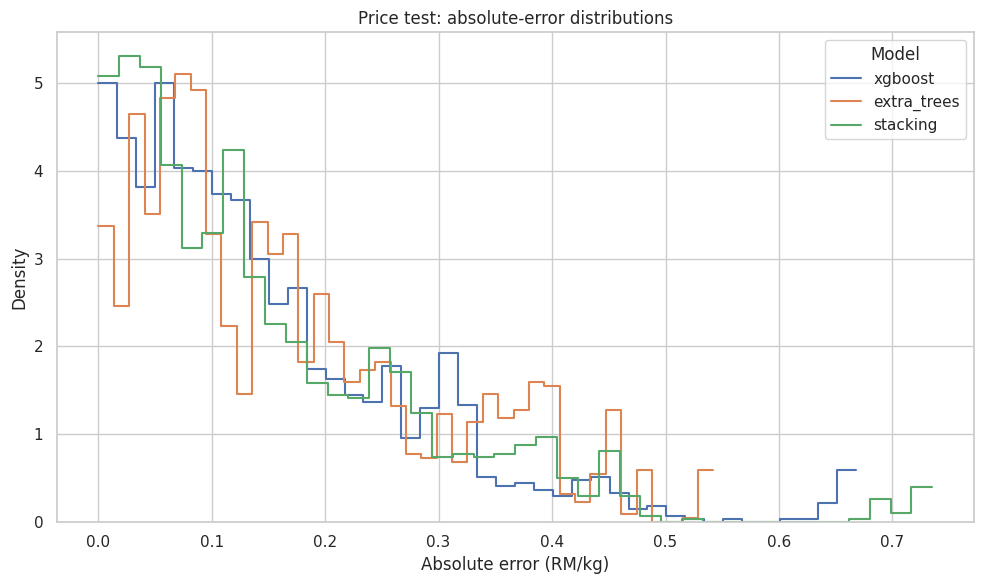

In [7]:
plt.figure(figsize=(10, 6))
for model_name, prediction_column in MODEL_COLUMNS.items():
    errors = (test[prediction_column] - actual).abs()
    sns.histplot(errors, bins=40, element="step", fill=False, stat="density", label=model_name)
plt.title("Price test: absolute-error distributions")
plt.xlabel("Absolute error (RM/kg)")
plt.ylabel("Density")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

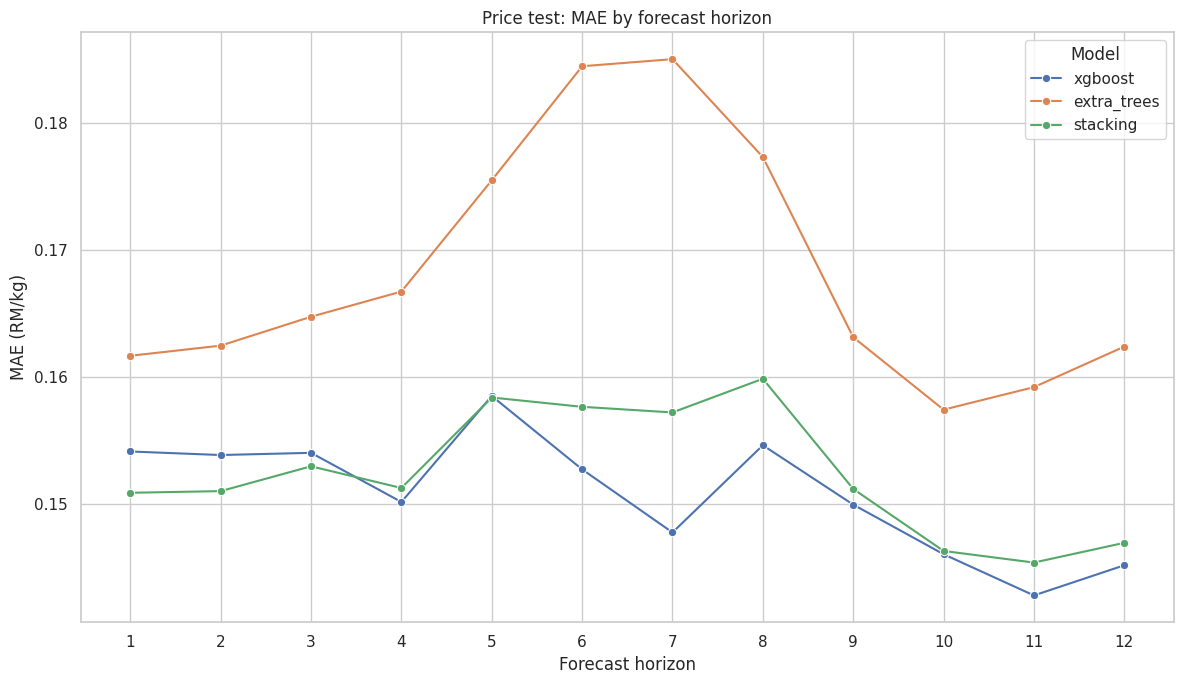

In [8]:
horizon_metrics = metrics[(metrics["split"].eq("test")) & (metrics["forecast_horizon"].ne("overall"))].copy()
horizon_metrics["forecast_horizon"] = horizon_metrics["forecast_horizon"].astype(int)
plt.figure(figsize=(12, 7))
sns.lineplot(data=horizon_metrics, x="forecast_horizon", y="mae", hue="model", marker="o")
plt.title("Price test: MAE by forecast horizon")
plt.xlabel("Forecast horizon")
plt.ylabel("MAE (RM/kg)")
plt.xticks(range(1, 13))
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## Save experiment artifacts

The saved Ridge model accepts two base-model predictions, not raw future features. It therefore cannot replace the two complete base pipelines by itself.

In [9]:
local_model_dir = LOCAL_ARTIFACT_DIR / "models"
local_prediction_dir = LOCAL_ARTIFACT_DIR / "predictions"
local_report_dir = LOCAL_ARTIFACT_DIR / "reports"
for directory in [local_model_dir, local_prediction_dir, local_report_dir]:
    directory.mkdir(parents=True, exist_ok=True)

model_file = local_model_dir / "experimental_ridge_stacker.joblib"
validation_file = local_prediction_dir / "stacking_validation_comparison.csv"
test_file = local_prediction_dir / "stacking_test_comparison.csv"
metrics_file = local_report_dir / "stacking_metrics.csv"
metadata_file = local_report_dir / "stacking_training_metadata.json"

joblib.dump(stacker, model_file)
validation.assign(absolute_error=(validation[TARGET_COLUMN] - validation["stacking_prediction"]).abs()).to_csv(validation_file, index=False)
test.assign(absolute_error=(test[TARGET_COLUMN] - test["stacking_prediction"]).abs()).to_csv(test_file, index=False)
metrics.to_csv(metrics_file, index=False)
metadata = {
    "model": "experimental_price_ridge_stacker",
    "status": "exploratory_not_deployable_without_base_models_and_time_ordered_oof_validation",
    "target": TARGET_COLUMN,
    "meta_features": META_FEATURES,
    "ridge_alpha": RIDGE_ALPHA,
    "fit_data": "base-model validation predictions",
    "evaluation_data": "base-model test predictions",
    "validation_metrics_are_in_sample": True,
    "base_model_fit_mismatch": "validation base models train-only; test base models train+validation",
    "ridge_intercept": float(stacker.intercept_),
    "ridge_coefficients": dict(zip(META_FEATURES, map(float, stacker.coef_))),
    "versions": {
        "python": platform.python_version(),
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__,
    },
}
metadata_file.write_text(json.dumps(metadata, indent=2), encoding="utf-8")

local_files = [model_file, validation_file, test_file, metrics_file, metadata_file]
for source in local_files:
    destination = DRIVE_ARTIFACT_DIR / source.parent.name / source.name
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)
    print(f"Saved: {destination}")

Saved: /content/drive/MyDrive/demand-forecasting/artifacts/price/models/experimental_ridge_stacker.joblib
Saved: /content/drive/MyDrive/demand-forecasting/artifacts/price/predictions/stacking_validation_comparison.csv
Saved: /content/drive/MyDrive/demand-forecasting/artifacts/price/predictions/stacking_test_comparison.csv
Saved: /content/drive/MyDrive/demand-forecasting/artifacts/price/reports/stacking_metrics.csv
Saved: /content/drive/MyDrive/demand-forecasting/artifacts/price/reports/stacking_training_metadata.json
